# Calibrating a camera for an industrial inspection station

**Denos Kume · Centrale Nantes · MSc Control and Robotics · Computer vision**

## Mission

An inspection engineer wants to relate positions on a flat fixture to pixels in a fixed camera. Using nine laboratory images of a chessboard with 30 mm squares, estimate a common camera matrix and one board-to-camera pose per view. Inspect where measured corners and their projected locations disagree before using the camera to measure parts.

The inspection station is a commissioning scenario. The measurements below come from the original MSc calibration dataset.

## Results at a glance

Nine views supplied 432 corners. The pooled RMS error was 0.534 px. View 7 had the largest RMS error at 0.859 px. The final cells generate the interactive review worksheet and the run manifest.

## Setup — Environment and Configuration


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=6, suppress=True)

In [2]:
SQUARE_SIZE_M = 0.03
INTERNAL_CORNERS_X = 8

INTERNAL_CORNERS_Y = 6
MIN_VALID_VIEWS = 3

In [3]:
OUTPUT_DIR = Path("outputs/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the Sorted JPEG Calibration Images


In [4]:
DATA_DIR = Path("data/calibration_images")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Calibration image directory not found: {DATA_DIR}"
    )
calibration_image_paths = sorted(
    path for path in DATA_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

if not calibration_image_paths:
    raise FileNotFoundError(
        f"No supported calibration images found in: {DATA_DIR}"
    )
readable_calibration_views = []
views = []

for image_path in calibration_image_paths:
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"[SKIPPED] {image_path.name}: image could not be read")
        continue

    readable_calibration_views.append(
        {
            "path": image_path,
            "name": image_path.name,
            "image": image,
        }
    )

if not readable_calibration_views:
    raise RuntimeError("No readable calibration images are available.")

print(f"Calibration files found : {len(calibration_image_paths)}")
print(f"Readable views          : {len(readable_calibration_views)}")

# All views must share the pixel geometry used by the intrinsic matrix.
if len({view["image"].shape[:2] for view in readable_calibration_views}) != 1:
    raise ValueError("Calibration views have different image sizes.")

Calibration files found : 9
Readable views          : 9


## 2. Detect and Refine Chessboard Corners


In [5]:
REFINE_CRITERIA = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    30,
    0.001,
)

def detect_and_refine_chessboard_corners(
    image,
    corners_x=INTERNAL_CORNERS_X,
    corners_y=INTERNAL_CORNERS_Y,
):
    """Detect and refine chessboard corners."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    found, corners = cv2.findChessboardCorners(
        gray,
        (corners_x, corners_y),
        None,
    )
    if not found or corners is None:
        return None
    # Sub-pixel refinement reduces localization error before homography estimation.
    refined = cv2.cornerSubPix(
        gray,
        corners,
        (11, 11),
        (-1, -1),
        REFINE_CRITERIA,
    )

    return refined.reshape(-1, 2)
views = []

for readable_calibration_view in readable_calibration_views:

    detected_corner_points = detect_and_refine_chessboard_corners(
        readable_calibration_view["image"]
    )
    if detected_corner_points is None:
        print(
            f"[SKIPPED] {readable_calibration_view['name']}: "
            "chessboard not detected"
        )
        continue

    view = readable_calibration_view.copy()
    view["image_points"] = detected_corner_points
    views.append(view)

    print(
        f"[OK] {view['name']}: "
        f"{detected_corner_points.shape[0]} refined corners"
    )
if len(views) < MIN_VALID_VIEWS:
    raise RuntimeError(
        f"At least {MIN_VALID_VIEWS} valid calibration views "
        f"are required; only {len(views)} were detected."
    )

print(f"\nValid calibration views: {len(views)}")

[OK] img0.jpg: 48 refined corners
[OK] img1.jpg: 48 refined corners
[OK] img2.jpg: 48 refined corners
[OK] img3.jpg: 48 refined corners
[OK] img4.jpg: 48 refined corners
[OK] img5.jpg: 48 refined corners
[OK] img6.jpg: 48 refined corners
[OK] img7.jpg: 48 refined corners
[OK] img8.jpg: 48 refined corners

Valid calibration views: 9


## 3. Build the Planar World Coordinates


In [6]:
def build_chessboard_plane_points(
    corners_x=INTERNAL_CORNERS_X,
    corners_y=INTERNAL_CORNERS_Y,
    square_size=SQUARE_SIZE_M,
):
    """Build chessboard plane points."""
    points = np.zeros(
        (corners_x * corners_y, 2),
        dtype=np.float64,
    )

    index = 0

    for y_index in range(corners_y):
        for x_index in range(corners_x):
            points[index, 0] = x_index * square_size
            points[index, 1] = y_index * square_size
            index += 1

    return points
chessboard_plane_points = build_chessboard_plane_points()

for view in views:
    view["plane_points"] = chessboard_plane_points.copy()

print(f"Planar points per view: {chessboard_plane_points.shape[0]}")
print(f"Square size: {SQUARE_SIZE_M:.3f} m")

Planar points per view: 48
Square size: 0.030 m


## 4. Compute $T_{\mathrm{image}}$ and $T_{\mathrm{plane}}$


Center and scale each point set to a mean distance of √2. This balances pixel and board coordinates before solving the linear system.

In [7]:
def convert_to_homogeneous_coordinates(points):
    """Convert to homogeneous coordinates."""
    points = np.asarray(points, dtype=float)

    homogeneous = np.ones((points.shape[0], 3), dtype=float)
    homogeneous[:, :2] = points

    return homogeneous

def compute_point_normalization_transform(points):
    """Compute point normalization transform."""
    points = np.asarray(points, dtype=float)

    centroid = np.mean(points, axis=0)
    shifted = points - centroid

    distances = np.linalg.norm(shifted, axis=1)
    mean_distance = np.mean(distances)
    # Reject degenerate point sets before normalization to avoid unstable scaling.
    if mean_distance < 1e-12:
        raise ValueError(
            "Point normalization is undefined for coincident points."
        )
    scale = np.sqrt(2.0) / mean_distance

    return np.array(
        [
            [scale, 0.0, -scale * centroid[0]],
            [0.0, scale, -scale * centroid[1]],
            [0.0, 0.0, 1.0],
        ],
        dtype=float,
    )
for view in views:

    T_image = compute_point_normalization_transform(view["image_points"])
    T_plane = compute_point_normalization_transform(view["plane_points"])

    view["T_image"] = T_image
    view["T_plane"] = T_plane
    view["normalized_image"] = (
        T_image @ convert_to_homogeneous_coordinates(view["image_points"]).T
    ).T
    view["normalized_plane"] = (
        T_plane @ convert_to_homogeneous_coordinates(view["plane_points"]).T
    ).T

print("Image and planar point normalization completed.")

Image and planar point normalization completed.


## 5. Build the DLT Matrix $Q$ and Solve $Q\mathbf{h}=0$ by SVD


In [8]:
def build_homography_dlt_matrix(normalized_plane, normalized_image):
    """Build homography dlt matrix."""
    n_points = normalized_image.shape[0]
    Q = np.zeros((2 * n_points, 9), dtype=float)
    for i in range(n_points):
        X, Y, _ = normalized_plane[i]
        u, v, _ = normalized_image[i]

        Q[2 * i] = [
            X, Y, 1.0,
            0.0, 0.0, 0.0,
            -u * X, -u * Y, -u,
        ]

        Q[2 * i + 1] = [
            0.0, 0.0, 0.0,
            X, Y, 1.0,
            -v * X, -v * Y, -v,
        ]

    return Q
for view in views:
    Q = build_homography_dlt_matrix(
        view["normalized_plane"],
        view["normalized_image"],
    )
    _, singular_values_Q, Vt_Q = np.linalg.svd(Q)

    h = Vt_Q[-1]
    H_normalized = h.reshape(3, 3)

    view["Q"] = Q
    view["h"] = h
    view["dlt_singular_values"] = singular_values_Q
    view["H_normalized"] = H_normalized

print("Normalized DLT solved for all views.")

Normalized DLT solved for all views.


## 6. Denormalize Each Homography


In [9]:
def denormalize_homography_matrix(H_normalized, T_image, T_plane):
    """Denormalize homography matrix."""

    H = (
        np.linalg.inv(T_image)
        @ H_normalized
        @ T_plane
    )
    if abs(H[2, 2]) < 1e-12:
        raise ValueError(
            "Degenerate homography: H[2, 2] is too close to zero."
        )
    H /= H[2, 2]
    return H
expected_corner_count = INTERNAL_CORNERS_X * INTERNAL_CORNERS_Y

for view in views:
    view["H"] = denormalize_homography_matrix(
        view["H_normalized"],
        view["T_image"],
        view["T_plane"],
    )
    if view["image_points"].shape != (expected_corner_count, 2):
        raise ValueError(
            f"Unexpected image-point shape for {view['name']}."
        )
    if view["plane_points"].shape != (expected_corner_count, 2):
        raise ValueError(
            f"Unexpected planar-point shape for {view['name']}."
        )
    if not np.all(np.isfinite(view["H"])):
        raise ValueError(
            f"Non-finite homography for {view['name']}."
        )

print("All homographies denormalized and validated.")

All homographies denormalized and validated.


## 7. Build the Zhang Matrix $V$ and Solve $Vb=0$ by SVD


Each view contributes two constraints because the first two rotation columns are orthogonal and have equal length. Different board tilts help constrain the shared camera matrix.

In [10]:
def build_zhang_constraint_vector(hi, hj):
    """Build zhang constraint vector."""
    return np.array(
        [
            hi[0] * hj[0],
            hi[0] * hj[1] + hi[1] * hj[0],
            hi[1] * hj[1],
            hi[2] * hj[0] + hi[0] * hj[2],
            hi[2] * hj[1] + hi[1] * hj[2],
            hi[2] * hj[2],
        ],
        dtype=float,
    )

def build_zhang_constraints_for_view(H):
    """Build zhang constraints for view."""
    h1 = H[:, 0]
    h2 = H[:, 1]

    v12 = build_zhang_constraint_vector(h1, h2)
    v11 = build_zhang_constraint_vector(h1, h1)
    v22 = build_zhang_constraint_vector(h2, h2)

    return np.vstack((v12, v11 - v22))
V = np.vstack(
    [build_zhang_constraints_for_view(view["H"]) for view in views]
)
_, singular_values, Vt = np.linalg.svd(V)
b = Vt[-1]

print("Constraint matrix shape:", V.shape)
print("\nSingular values:")
print(singular_values)
print("\nResidual norm ||Vb||:")
print(np.linalg.norm(V @ b))
print("\nEstimated b vector:")
print(b)

Constraint matrix shape: (18, 6)

Singular values:
[10570467.861231  9166881.090538  1672254.732288    10850.573156
     4170.700828        0.073745]

Residual norm ||Vb||:
0.07374462973552971

Estimated b vector:
[-0.000002  0.       -0.000002  0.000698  0.000516 -1.      ]


## 8. Recover $\alpha,\beta,\gamma,u_0,v_0$ and Construct $K$


In [11]:
b11, b12, b22, b13, b23, b33 = b
denominator = b11 * b22 - b12**2
if abs(denominator) < 1e-12:
    raise ValueError("Degenerate intrinsic calibration constraints.")
v0 = (b12 * b13 - b11 * b23) / denominator
lambda_ = b33 - (
    b13**2
    + v0 * (b12 * b13 - b11 * b23)
) / b11

if lambda_ / b11 <= 0 or lambda_ * b11 / denominator <= 0:
    b = -b
    b11, b12, b22, b13, b23, b33 = b

    denominator = b11 * b22 - b12**2
    v0 = (b12 * b13 - b11 * b23) / denominator

    lambda_ = b33 - (
        b13**2
        + v0 * (b12 * b13 - b11 * b23)
    ) / b11
alpha = np.sqrt(lambda_ / b11)
beta = np.sqrt(lambda_ * b11 / denominator)
gamma = -b12 * alpha**2 * beta / lambda_

u0 = gamma * v0 / beta - b13 * alpha**2 / lambda_
K = np.array(
    [
        [alpha, gamma, u0],
        [0.0, beta, v0],
        [0.0, 0.0, 1.0],
    ],
    dtype=float,
)

print("Intrinsic parameters")
print("--------------------")
print(f"alpha : {alpha:.6f}")
print(f"beta  : {beta:.6f}")
print(f"gamma : {gamma:.6f}")
print(f"u0    : {u0:.6f}")
print(f"v0    : {v0:.6f}")

print("\nIntrinsic matrix K:")
print(K)

Intrinsic parameters
--------------------
alpha : 547.056831
beta  : 548.306822
gamma : 0.670827
u0    : 319.888557
v0    : 237.554629

Intrinsic matrix K:
[[547.056831   0.670827 319.888557]
 [  0.       548.306822 237.554629]
 [  0.         0.         1.      ]]


## 9. Recover $R$ and $t$ for Every Retained View


In [12]:
def recover_camera_pose(K, H):
    """Recover camera pose."""
    K_inv = np.linalg.inv(K)

    h1 = H[:, 0]
    h2 = H[:, 1]
    h3 = H[:, 2]
    lambda_p = 1.0 / np.linalg.norm(K_inv @ h1)

    r1 = lambda_p * (K_inv @ h1)
    r2 = lambda_p * (K_inv @ h2)
    r3 = np.cross(r1, r2)

    R_approx = np.column_stack((r1, r2, r3))

    # Project the approximate rotation onto SO(3) to enforce a valid orthonormal rotation.
    U, _, Vt = np.linalg.svd(R_approx)
    R = U @ Vt
    if np.linalg.det(R) < 0:
        U[:, -1] *= -1
        R = U @ Vt

    t = lambda_p * (K_inv @ h3)

    return R, t
for view in views:
    R, t = recover_camera_pose(K, view["H"])

    view["R"] = R
    view["t"] = t

    print(view["name"])
    print("R =")
    print(R)
    print("t =", t)
    print("-" * 60)

img0.jpg
R =
[[ 0.913569  0.100015 -0.394194]
 [-0.095269  0.994948  0.031648]
 [ 0.395368  0.008642  0.918482]]
t = [-0.128624 -0.05972   0.340668]
------------------------------------------------------------
img1.jpg
R =
[[ 0.913582  0.098342 -0.394584]
 [-0.094409  0.995099  0.029423]
 [ 0.395543  0.010372  0.918389]]
t = [-0.128361 -0.059664  0.34046 ]
------------------------------------------------------------
img2.jpg
R =
[[ 0.998455 -0.051583  0.020649]
 [ 0.050658  0.692462 -0.719674]
 [ 0.022825  0.719608  0.694005]]
t = [-0.125541 -0.063765  0.282383]
------------------------------------------------------------
img3.jpg
R =
[[ 0.99837  -0.05116   0.025314]
 [ 0.053681  0.690788 -0.721062]
 [ 0.019403  0.721245  0.692408]]
t = [-0.125603 -0.063131  0.28223 ]
------------------------------------------------------------
img4.jpg
R =
[[ 0.945514 -0.119184  0.302981]
 [ 0.100184  0.991942  0.077556]
 [-0.309783 -0.042977  0.949836]]
t = [-0.118615 -0.092624  0.394739]
-----------

## 10. Reproject the $Z=0$ Calibration Points


Project the same 48 board points back into each image. A residual is the Euclidean distance from a detected corner to its projected position, measured in pixels.

In [13]:
for view in views:
    chessboard_xy_points = view["plane_points"]
    chessboard_xyz_points = np.column_stack(
        (
            chessboard_xy_points,
            np.zeros(chessboard_xy_points.shape[0]),
        )
    )
    camera_frame_points = (
        chessboard_xyz_points @ view["R"].T
        + view["t"]
    )

    projected_h = camera_frame_points @ K.T
    if np.any(np.abs(projected_h[:, 2]) < 1e-12):
        raise ValueError(
            f"Invalid homogeneous depth during reprojection for {view['name']}."
        )
    reprojected_image_points = (
        projected_h[:, :2]
        / projected_h[:, 2:3]
    )

    view["world_xyz"] = chessboard_xyz_points
    view["projected"] = reprojected_image_points

print(f"Reprojected calibration views: {len(views)}")

Reprojected calibration views: 9


## 11. Compute Point-wise Errors, Mean Error and RMSE


In [14]:
for view in views:
    residuals = (
        view["projected"]
        - view["image_points"]
    )
    errors = np.linalg.norm(
        residuals,
        axis=1,
    )

    view["residuals"] = residuals
    view["errors"] = errors
    view["mean_error"] = float(errors.mean())
    view["rmse"] = float(
        np.sqrt(np.mean(errors**2))
    )

    print(view["name"])
    print(
        f"Mean reprojection error : "
        f"{view['mean_error']:.4f} px"
    )
    print(
        f"Reprojection RMSE       : "
        f"{view['rmse']:.4f} px"
    )
    print("-" * 60)

img0.jpg
Mean reprojection error : 0.2561 px
Reprojection RMSE       : 0.3029 px
------------------------------------------------------------
img1.jpg
Mean reprojection error : 0.2343 px
Reprojection RMSE       : 0.2772 px
------------------------------------------------------------
img2.jpg
Mean reprojection error : 0.4690 px
Reprojection RMSE       : 0.5247 px
------------------------------------------------------------
img3.jpg
Mean reprojection error : 0.5472 px
Reprojection RMSE       : 0.6085 px
------------------------------------------------------------
img4.jpg
Mean reprojection error : 0.3844 px
Reprojection RMSE       : 0.4444 px
------------------------------------------------------------
img5.jpg
Mean reprojection error : 0.2508 px
Reprojection RMSE       : 0.2788 px
------------------------------------------------------------
img6.jpg
Mean reprojection error : 0.6027 px
Reprojection RMSE       : 0.7281 px
------------------------------------------------------------
img7.j

In [15]:
all_reprojection_errors = np.concatenate(
    [view["errors"] for view in views]
)
overall_mean_error = float(
    all_reprojection_errors.mean()
)
overall_rmse = float(
    np.sqrt(np.mean(all_reprojection_errors**2))
)

print("Calibration summary")
print("-------------------")
print(f"Valid calibration views : {len(views)}")
print(f"Calibration points       : {len(all_reprojection_errors)}")
print(
    f"Mean reprojection error  : "
    f"{overall_mean_error:.4f} px"
)
print(
    f"Overall RMSE             : "
    f"{overall_rmse:.4f} px"
)

Calibration summary
-------------------
Valid calibration views : 9
Calibration points       : 432
Mean reprojection error  : 0.4340 px
Overall RMSE             : 0.5339 px


## 12. Inspect calibration geometry and residuals


In [16]:
REQUIRED_OUTPUTS = [
    "detected_chessboard_corners.png",
    "homography_estimation_pipeline.png",
    "estimated_camera_poses.png",
    "reprojection_results.png",
    "mean_reprojection_error_by_view.png",
    "reprojection_error_distribution.png",
]

print("Diagnostic figures to generate:")
for output_name in REQUIRED_OUTPUTS:
    print(f"  - {output_name}")

Diagnostic figures to generate:
  - detected_chessboard_corners.png
  - homography_estimation_pipeline.png
  - estimated_camera_poses.png
  - reprojection_results.png
  - mean_reprojection_error_by_view.png
  - reprojection_error_distribution.png


### 12.1 Homography Estimation Pipeline

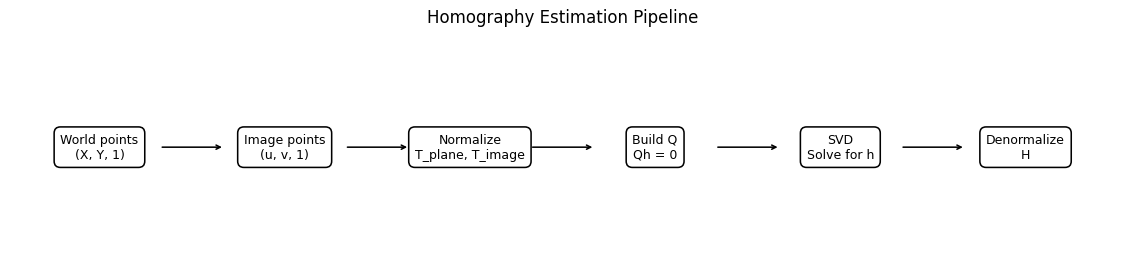

In [17]:
fig, ax = plt.subplots(figsize=(15, 3.5))
ax.axis("off")
labels = [
    "World points\n(X, Y, 1)",
    "Image points\n(u, v, 1)",
    "Normalize\nT_plane, T_image",
    "Build Q\nQh = 0",
    "SVD\nSolve for h",
    "Denormalize\nH",
]

x_positions = np.linspace(0.08, 0.92, len(labels))

for x, label in zip(x_positions, labels):
    ax.text(
        x,
        0.5,
        label,
        ha="center",
        va="center",
        fontsize=12,
        transform=ax.transAxes,
        bbox={
            "boxstyle": "round,pad=0.5",
            "fill": False,
            "linewidth": 1.5,
        },
    )

for start, end in zip(x_positions[:-1], x_positions[1:]):
    ax.annotate(
        "",
        xy=(end - 0.055, 0.5),
        xytext=(start + 0.055, 0.5),
        xycoords=ax.transAxes,
        arrowprops={
            "arrowstyle": "->",
            "linewidth": 1.5,
        },
    )

ax.set_title("Homography Estimation Pipeline", fontsize=16, pad=20)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "homography_estimation_pipeline.png",
    dpi=95,
    bbox_inches="tight",
)

plt.show()

### 12.2 Mean Reprojection Error by View

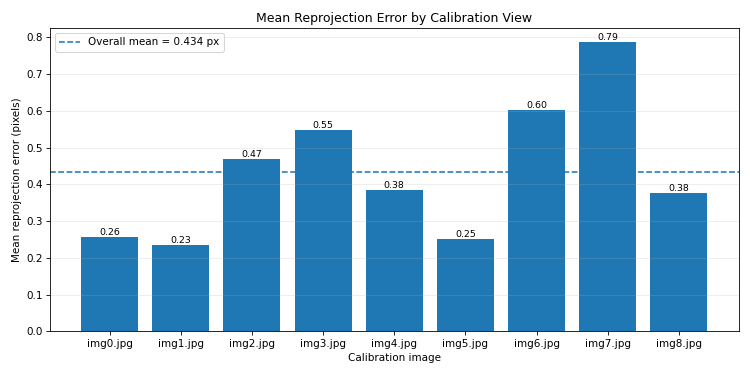

In [18]:
image_names = [
    view["name"]
    for view in views
]
mean_reprojection_errors = [
    view["mean_error"]
    for view in views
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    image_names,
    mean_reprojection_errors,
)

ax.axhline(
    overall_mean_error,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall mean = {overall_mean_error:.3f} px",
)

for bar, value in zip(bars, mean_reprojection_errors):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_title("Mean Reprojection Error by Calibration View")
ax.set_xlabel("Calibration image")
ax.set_ylabel("Mean reprojection error (pixels)")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "mean_reprojection_error_by_view.png",
    dpi=95,
    bbox_inches="tight",
)

plt.show()

### 12.3 Reprojection Error Distribution

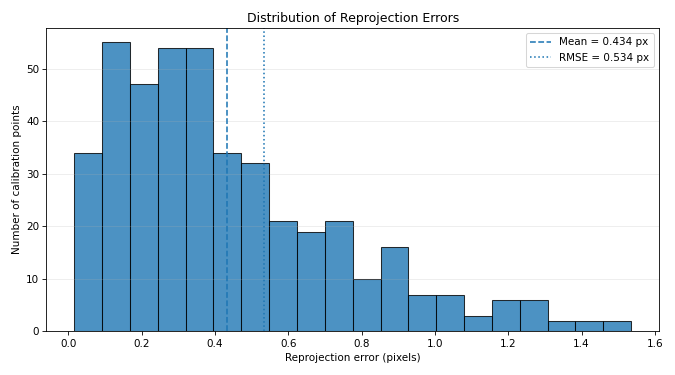

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    all_reprojection_errors,
    bins=20,
    edgecolor="black",
    alpha=0.8,
)

ax.axvline(
    overall_mean_error,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {overall_mean_error:.3f} px",
)

ax.axvline(
    overall_rmse,
    linestyle=":",
    linewidth=1.5,
    label=f"RMSE = {overall_rmse:.3f} px",
)

ax.set_title("Distribution of Reprojection Errors")
ax.set_xlabel("Reprojection error (pixels)")
ax.set_ylabel("Number of calibration points")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reprojection_error_distribution.png",
    dpi=95,
    bbox_inches="tight",
)

plt.show()

### 12.4 Detected Chessboard Corners

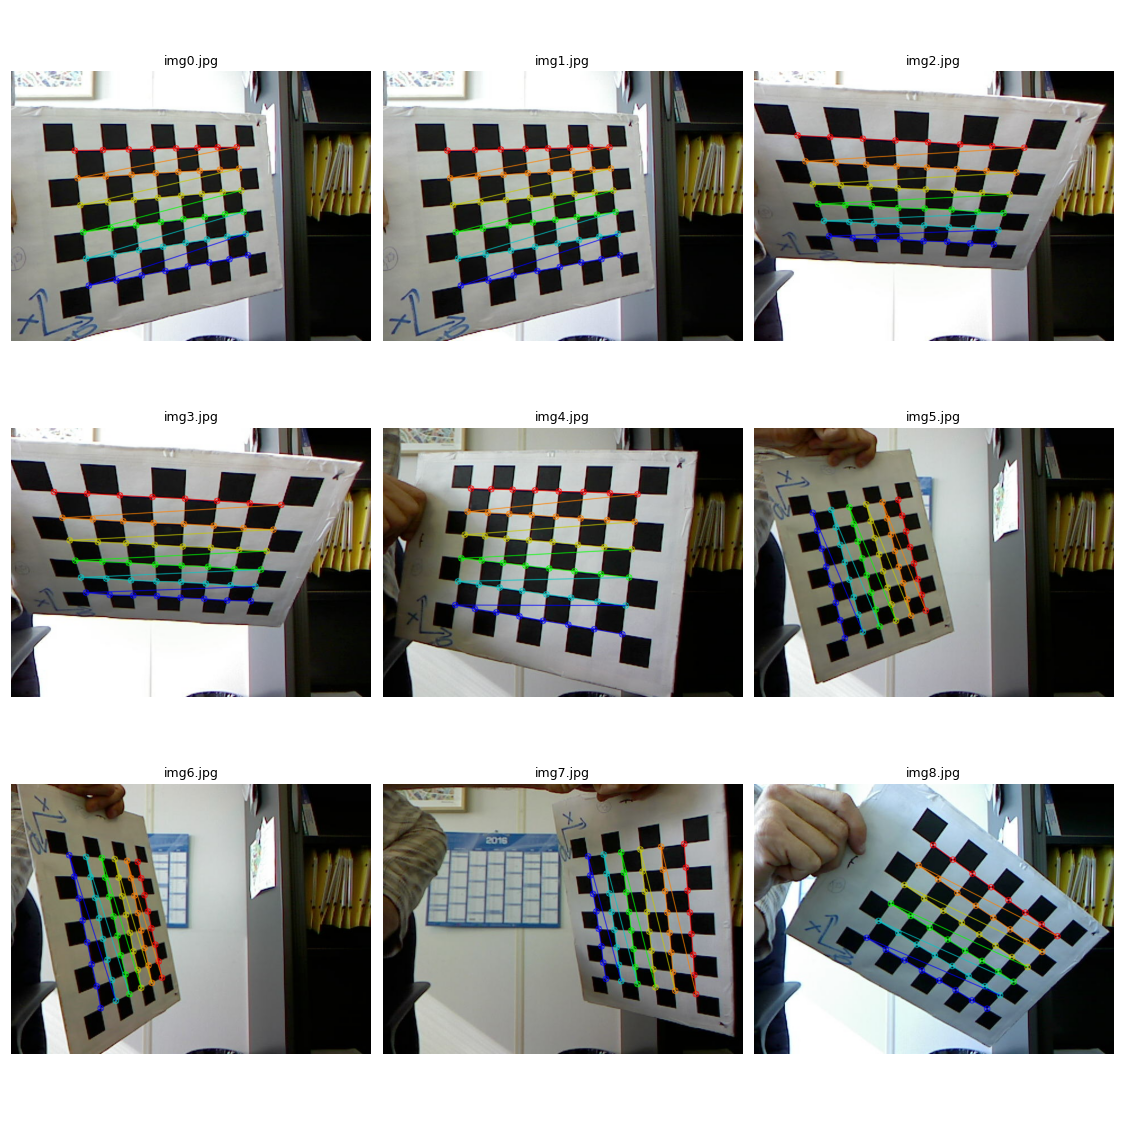

In [20]:
number_of_views = len(views)
plot_columns = 3
plot_rows = int(np.ceil(number_of_views / plot_columns))

fig, axes = plt.subplots(
    plot_rows,
    plot_columns,
    figsize=(15, 5 * plot_rows),
)

axes = np.asarray(axes).reshape(-1)

for ax, view in zip(axes, views):

    visual = view["image"].copy()
    corners = (
        view["image_points"]
        .reshape(-1, 1, 2)
        .astype(np.float32)
    )

    cv2.drawChessboardCorners(
        visual,
        (
            INTERNAL_CORNERS_X,
            INTERNAL_CORNERS_Y,
        ),
        corners,
        True,
    )

    visual_rgb = cv2.cvtColor(
        visual,
        cv2.COLOR_BGR2RGB,
    )

    ax.imshow(visual_rgb)
    ax.set_title(view["name"])
    ax.axis("off")

for ax in axes[number_of_views:]:
    ax.axis("off")

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "detected_chessboard_corners.png",
    dpi=95,
    bbox_inches="tight",
)

plt.show()

### 12.5 Estimated Camera Poses

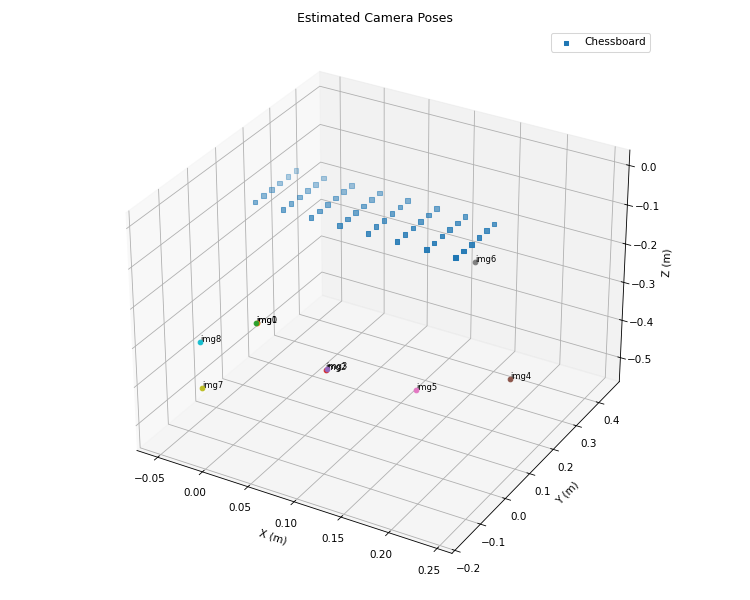

In [21]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
reference_chessboard_xy_points = views[0]["plane_points"]
reference_chessboard_xyz_points = np.column_stack(
    (
        reference_chessboard_xy_points,
        np.zeros(reference_chessboard_xy_points.shape[0]),
    )
)

ax.scatter(
    reference_chessboard_xyz_points[:, 0],
    reference_chessboard_xyz_points[:, 1],
    reference_chessboard_xyz_points[:, 2],
    marker="s",
    label="Chessboard",
)

for view in views:
    R = view["R"]
    t = view["t"]

    camera_center = -R.T @ t

    ax.scatter(
        camera_center[0],
        camera_center[1],
        camera_center[2],
        marker="o",
    )

    ax.text(
        camera_center[0],
        camera_center[1],
        camera_center[2],
        view["path"].stem,
        fontsize=8,
    )

ax.set_title("Estimated Camera Poses")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "estimated_camera_poses.png",
    dpi=95,
    bbox_inches="tight",
)

plt.show()

### 12.6 Detected vs Reprojected Points

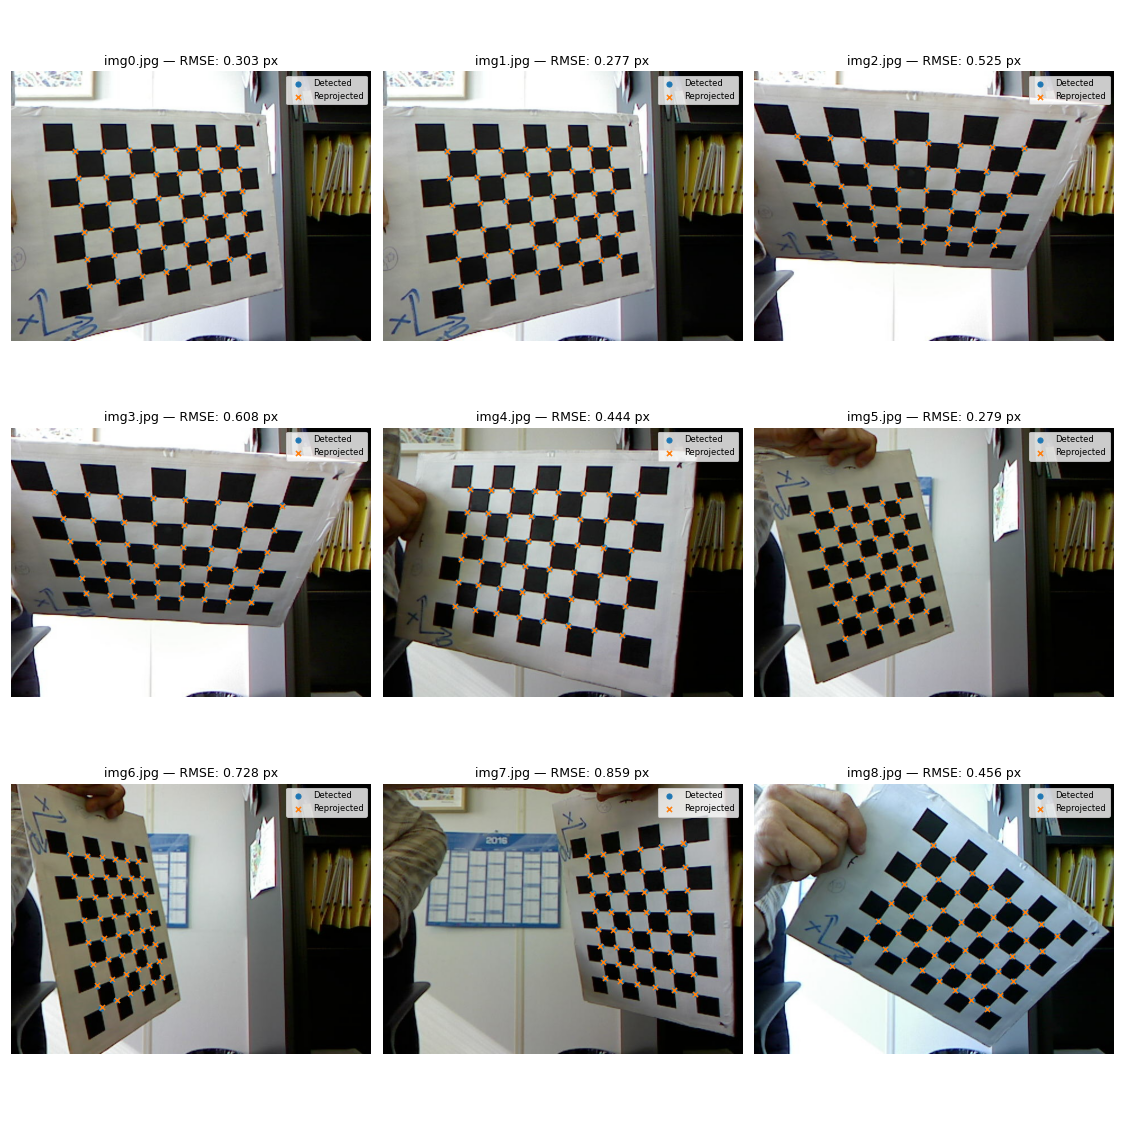

In [22]:
number_of_views = len(views)
plot_columns = 3
plot_rows = int(np.ceil(number_of_views / plot_columns))

fig, axes = plt.subplots(
    plot_rows,
    plot_columns,
    figsize=(15, 5 * plot_rows),
)

axes = np.asarray(axes).reshape(-1)

for ax, view in zip(axes, views):

    image_rgb = cv2.cvtColor(
        view["image"],
        cv2.COLOR_BGR2RGB,
    )

    ax.imshow(image_rgb)

    ax.scatter(
        view["image_points"][:, 0],
        view["image_points"][:, 1],
        s=24,
        marker="o",
        label="Detected",
    )

    ax.scatter(
        view["projected"][:, 0],
        view["projected"][:, 1],
        s=24,
        marker="x",
        label="Reprojected",
    )

    ax.set_title(
        f"{view['name']} — RMSE: {view['rmse']:.3f} px"
    )
    ax.axis("off")
    ax.legend(fontsize=8)

for ax in axes[number_of_views:]:
    ax.axis("off")

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reprojection_results.png",
    dpi=95,
    bbox_inches="tight",
)

plt.show()

## 13. Validate the recovered geometry and diagnostic outputs


In [23]:
if K.shape != (3, 3) or not np.all(np.isfinite(K)):
    raise ValueError("Invalid intrinsic matrix K.")

for view in views:

    if not np.all(np.isfinite(view["H"])):
        raise ValueError(
            f"Non-finite homography for {view['name']}."
        )

    R = view["R"]
    if not np.allclose(
        R.T @ R,
        np.eye(3),
        atol=1e-6,
    ):
        raise ValueError(
            f"Non-orthonormal rotation for {view['name']}."
        )
    if not np.isclose(
        np.linalg.det(R),
        1.0,
        atol=1e-6,
    ):
        raise ValueError(
            f"Invalid rotation determinant for {view['name']}."
        )
    if not np.all(np.isfinite(view["errors"])):
        raise ValueError(
            f"Non-finite residuals for {view['name']}."
        )

missing = [
    name
    for name in REQUIRED_OUTPUTS
    if not (OUTPUT_DIR / name).exists()
]
if missing:
    raise FileNotFoundError(
        "Missing outputs: " + ", ".join(missing)
    )

print("All Camera Calibration validation checks passed.")

All Camera Calibration validation checks passed.


## Can the calibration predict corners in a new pose?

Leave one board view out and fit each camera model using the other eight views. In the omitted view, estimate the board pose from 24 alternating corners, then score the other 24. This keeps the scored corners out of both the intrinsic calibration and the held-out pose fit. Repeat for all nine views.

Compare the linear Zhang solution with OpenCV’s nonlinear calibration, which estimates radial and tangential lens distortion and fixes skew to zero. The comparison measures the combined effect of these modeling choices. All views come from one acquisition.

Linear Zhang: 0.3945 px pooled held-out RMS
Refined with distortion: 0.3524 px pooled held-out RMS


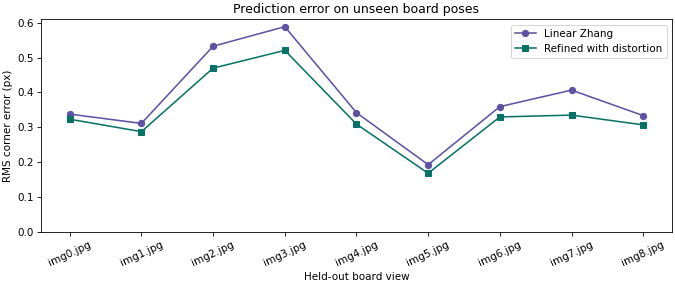

In [24]:
import csv

def fit_linear_camera(training_views):
    """Recover the intrinsic matrix from Zhang constraints on the training poses."""
    constraints = np.vstack([build_zhang_constraints_for_view(view["H"]) for view in training_views])
    coefficients = np.linalg.svd(constraints, full_matrices=False)[2][-1]
    b11, b12, b22, b13, b23, b33 = coefficients
    inverse_metric = np.array([[b11, b12, b13], [b12, b22, b23], [b13, b23, b33]])
    # B is proportional to inv(K).T @ inv(K). Fix its arbitrary sign before Cholesky.
    camera_matrix = np.linalg.inv(np.linalg.cholesky(np.sign(b11) * inverse_metric).T)
    return camera_matrix / camera_matrix[2, 2]


def held_out_corner_errors(board_xyz, image_xy, pose_mask, camera_matrix, distortion):
    """Fit the held-out pose on interleaved anchors and score the complementary corners."""
    # Remove the intrinsic transform explicitly to preserve the linear model's nonzero skew.
    rays = np.linalg.solve(camera_matrix, convert_to_homogeneous_coordinates(image_xy).T).T[:, :2]
    converged, rotation, translation = cv2.solvePnP(
        board_xyz[pose_mask], np.ascontiguousarray(rays[pose_mask]), np.eye(3), distortion)
    if not converged:
        raise ValueError("Could not recover the held-out pose.")
    projected_rays, _ = cv2.projectPoints(board_xyz[~pose_mask], rotation, translation, np.eye(3), distortion)
    pixels = convert_to_homogeneous_coordinates(projected_rays.reshape(-1, 2)) @ camera_matrix.T
    return np.linalg.norm(pixels[:, :2] - image_xy[~pose_mask], axis=1)


board_xyz = np.column_stack((views[0]["plane_points"], np.zeros(len(views[0]["plane_points"]))))
row_index, column_index = np.indices((INTERNAL_CORNERS_Y, INTERNAL_CORNERS_X))
pose_mask = ((row_index + column_index) % 2 == 0).ravel()
image_size_px = views[0]["image"].shape[1::-1]
transfer_rows = []
for held_out in views:
    training_views = [view for view in views if view is not held_out]
    linear_camera = fit_linear_camera(training_views)
    _, refined_camera, distortion, _, _ = cv2.calibrateCamera(
        [board_xyz.astype(np.float32)] * len(training_views),
        [view["image_points"].astype(np.float32) for view in training_views], image_size_px, None, None)
    for method, camera_matrix, coefficients in [
        ("Linear Zhang", linear_camera, None),
        ("Refined with distortion", refined_camera, distortion),
    ]:
        errors = held_out_corner_errors(board_xyz, held_out["image_points"], pose_mask, camera_matrix, coefficients)
        transfer_rows.append({"image": held_out["name"], "model": method, "scored_corners": len(errors),
                              "rmse_px": float(np.sqrt(np.mean(errors**2))), "max_error_px": float(errors.max())})

transfer_path = OUTPUT_DIR.parent / "held_out_view_errors.csv"
with transfer_path.open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(transfer_rows[0]))
    writer.writeheader()
    writer.writerows(transfer_rows)
# Each held-out view contributes the same number of test corners.
transfer_scores = {}
figure, axes = plt.subplots(figsize=(9, 3.8), layout="constrained")
for method, color, marker in [("Linear Zhang", "#5d52a3", "o"), ("Refined with distortion", "#077367", "s")]:
    rows = [row for row in transfer_rows if row["model"] == method]
    rms_errors = np.array([row["rmse_px"] for row in rows])
    transfer_scores[method] = float(np.sqrt(np.mean(rms_errors**2)))
    axes.plot([row["image"] for row in rows], rms_errors, marker=marker, color=color, label=method)
    print(f"{method}: {transfer_scores[method]:.4f} px pooled held-out RMS")
axes.set(xlabel="Held-out board view", ylabel="RMS corner error (px)", title="Prediction error on unseen board poses", ylim=(0, None))
axes.tick_params(axis="x", rotation=25)
axes.legend()
figure.savefig(OUTPUT_DIR / "held_out_view_errors.png", dpi=130)
plt.show()


## Export and review

Save the fitted geometry, the per-view errors and an offline review page containing every retained image.

In [25]:
import base64
import csv
import hashlib
import importlib.metadata
import platform
import html
import json

results_directory = Path("outputs")
review_directory = Path("review")
review_directory.mkdir(exist_ok=True)

# Keep camera parameters and poses together so downstream users know the frame convention.
calibration = {
    "model": "linear pinhole, no distortion coefficients estimated",
    "image_size_px": list(views[0]["image"].shape[1::-1]),
    "board_square_size_m": SQUARE_SIZE_M,
    "camera_matrix_px": K.tolist(),
    "pose_convention": "camera_point = rotation @ board_point + translation_m",
    "mean_error_px": overall_mean_error,
    "rmse_px": overall_rmse,
    "poses": {view["name"]: {"rotation": view["R"].tolist(), "translation_m": view["t"].tolist()}
              for view in views},
}
(results_directory / "calibration.json").write_text(json.dumps(calibration, indent=2))
with (results_directory / "view_errors.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["image", "corners", "mean_error_px", "rmse_px"])
    for view in views:
        writer.writerow([view["name"], len(view["errors"]), view["mean_error"], view["rmse"]])


def file_digest(path):
    """Identify the exact bytes used for this calibration run."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


run_manifest = {
    "model": calibration["model"],
    "board_inner_corners": [INTERNAL_CORNERS_X, INTERNAL_CORNERS_Y],
    "square_pitch_m": SQUARE_SIZE_M,
    "subpixel_window_px": [11, 11],
    "software": {name: importlib.metadata.version(name) for name in
                 ["opencv-python-headless", "numpy", "matplotlib"]},
    "python": platform.python_version(),
    "inputs": {path.name: file_digest(path) for path in calibration_image_paths},
    "retained_views": [view["name"] for view in views],
    "results": {path.name: file_digest(path) for path in
                [results_directory / "calibration.json", results_directory / "view_errors.csv", transfer_path, OUTPUT_DIR / "held_out_view_errors.png"]},
}
manifest_text = json.dumps(run_manifest, indent=2)
(review_directory / "run_manifest.json").write_text(manifest_text)
run_id = hashlib.sha256(manifest_text.encode()).hexdigest()[:16]
with (review_directory / "reader_template.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["image", "mean_error_px", "rmse_px", "review_status", "observations"])
    for view in views:
        writer.writerow([view["name"], view["mean_error"], view["rmse"], "Pending", ""])


def render_view_review(view):
    """Embed the source image and corner locations in the same pixel coordinate system."""
    height, width = view["image"].shape[:2]
    encoded_image = base64.b64encode(view["path"].read_bytes()).decode("ascii")
    import mimetypes
    image_type = mimetypes.guess_type(str(view["path"]))[0] or "image/jpeg"
    detected = "".join(f'<circle cx="{x:.3f}" cy="{y:.3f}" r="4"/>' for x, y in view["image_points"])
    projected = "".join(f'<path d="M{x-3:.3f},{y-3:.3f}l6,6m-6,0l6,-6"/>' for x, y in view["projected"])
    name = html.escape(view["name"])
    return f"""<details data-name="{name}" data-mean="{view['mean_error']:.6f}" data-rmse="{view['rmse']:.6f}"><summary>{name} · {len(view['errors'])} corners · RMSE {view['rmse']:.4f} px</summary>
    <p>Mean error {view['mean_error']:.4f} px · Largest corner error {max(view['errors']):.4f} px</p>
    <svg viewBox="0 0 {width} {height}" role="img" aria-label="Corner overlay for {name}">
    <image width="{width}" height="{height}" href="data:{image_type};base64,{encoded_image}"/>
    <g class="marks" fill="none" stroke-width="1.8"><g stroke="#00ffff">{detected}</g>
    <g stroke="#ff782d">{projected}</g></g></svg><fieldset><legend>View assessment</legend><label>Review status <select><option>Pending</option><option>Reviewed</option><option>Investigate</option></select></label>
    <label>Observations <textarea placeholder="Record corner alignment, board coverage or a reason to reacquire this view."></textarea></label></fieldset></details>"""


review_sections = "".join(render_view_review(view) for view in views)
worksheet_script = r"""
const panels = [...document.querySelectorAll("details")];
const storageKey = "camera-calibration-review-" + document.body.dataset.run;
const statusLine = document.querySelector("#progress");
let saved = {};
try { saved = JSON.parse(localStorage.getItem(storageKey)) || {}; } catch {}
function collectRows() {
  return panels.map(panel => [panel.dataset.name, panel.dataset.mean, panel.dataset.rmse,
    panel.querySelector("select").value, panel.querySelector("textarea").value]);
}
function updateProgress() {
  const rows = collectRows();
  const reviewed = rows.filter(row => row[3] !== "Pending").length;
  statusLine.textContent = reviewed + " of " + rows.length + " views reviewed";
  try {
    localStorage.setItem(storageKey, JSON.stringify(Object.fromEntries(rows.map(row => [row[0], row.slice(3)]))));
  } catch { statusLine.textContent += " · Export CSV to keep your notes"; }
}
for (const panel of panels) {
  const previous = saved[panel.dataset.name];
  if (Array.isArray(previous)) {
    panel.querySelector("select").value = previous[0];
    panel.querySelector("textarea").value = previous[1];
  }
  panel.addEventListener("input", updateProgress);
}
updateProgress();
document.querySelector("#export").onclick = () => {
  const rows = [["image","mean_error_px","rmse_px","review_status","observations"], ...collectRows()];
  const quote = value => '"' + String(value).replaceAll('"','""') + '"';
  const csv = rows.map(row => row.map(quote).join(",")).join("\r\n");
  const url = URL.createObjectURL(new Blob([csv], {type:"text/csv;charset=utf-8"}));
  const link = document.createElement("a");
  link.href = url; link.download = "calibration-review.csv"; link.click();
  setTimeout(() => URL.revokeObjectURL(url), 1000);
};
"""
review_page = f"""<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Inspection camera calibration | Engineering review</title><style>
*{{box-sizing:border-box}}body{{max-width:860px;margin:36px auto;padding:0 20px;color:#173249;background:#f7fafb;font:17px/1.5 system-ui}}
h1{{line-height:1.1}}header{{border-top:5px solid #12685d}}details{{background:white;margin:10px 0;border:1px solid #bfcfce;border-radius:5px;padding:12px}}
summary,label{{cursor:pointer}}svg{{width:100%;height:auto}}#markers:not(:checked)~details .marks{{display:none}}fieldset{{display:grid;gap:.65rem;border:1px solid #bed1cd}}textarea{{display:block;width:100%;min-height:4em}}select,textarea,button{{font:inherit}}button{{padding:.4em .8em}} </style><body data-run="{run_id}">
<header><h1>Inspection camera calibration</h1><p>Denos Kume · Centrale Nantes · MSc Control and Robotics · Industrial inspection case study</p></header>
<h2>Held-out view test</h2><p>Eight training poses per fold. Of the 48 corners on the ninth pose, 24 place the board and 24 test the prediction. Across nine folds, pooled RMS is {transfer_scores['Linear Zhang']:.3f} px for linear Zhang and {transfer_scores['Refined with distortion']:.3f} px for nonlinear calibration with distortion.</p>
<h2>Calibration fit</h2><p>{len(views)} views · {len(all_reprojection_errors)} corners · Mean {overall_mean_error:.4f} px · RMS {overall_rmse:.4f} px.</p>
<p>Use the board images to inspect the fit before evaluating dimensional accuracy on an independent reference part.
Open a view to compare detected corners (cyan circles) with projected locations (orange crosses).</p>
<p>Expand each photograph, inspect corner alignment and record observations. Drafts are saved in this browser when available.</p>
<button type="button" id="export">Export worksheet (CSV)</button> <span id="progress" role="status"></span><hr>
<input type="checkbox" id="markers" checked> <label for="markers">Show corner overlays</label>{review_sections}<script>{worksheet_script}</script></body></html>"""
(review_directory / "index.html").write_text(review_page, encoding="utf-8")
print("Saved calibration parameters, per-view measurements and standalone HTML review.")


Saved calibration parameters, per-view measurements and standalone HTML review.


## Results and experience gained

The fitted model reproduced 432 measured corners across nine images with a mean error of 0.434 px and an RMS error of 0.534 px. Image 7 had the largest view-level RMS error (0.859 px). Comparing each view with the pooled score helped identify where to inspect feature localization and model fit.

The exercise connects three practical skills: conditioning a homography estimate, recovering physically valid rotations and interpreting residuals in image coordinates. These are fitting residuals on the calibration views. A dimensional acceptance decision would require independent measurements across the work area, a specified part tolerance and an assessment of lens distortion.